# GLOF critical area — training and testing

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

In [2]:
glof = pd.read_csv("glof_clean.csv")
glof.head()

,lake_id,year,lake_area_km2,elevation_m,perimeter_km,area_uncertainty_km2,expansion_rate_km2yr,lake_volume_1e6_m3,dam_height_m,shape_index,...,lon,lat,yrs_capped,already_past_critical,glof_within_50yr,mean_depth,volume_dam,volume_gap,uncertainty_frac,expansion_frac
0,GLO_80.85718_29.91975,2024,0.004988,4782.9,0.36469,0.003,0.0,0.0609,15.00,1.4567,...,80.85718,29.91975,1,0,0,12.209302,0.913500,-0.013920,0.601443,0.0
1,GLO_80.87763_30.04078,2017,0.055611,4448.8,1.25819,0.010,0.0,1.1127,15.99,1.5051,...,80.87763,30.04078,1,0,0,20.008631,17.792073,0.223480,0.179821,0.0
2,GLO_80.87763_30.04078,2018,0.052037,4448.8,1.23996,0.010,0.0,1.0261,15.83,1.5334,...,80.87763,30.04078,1,0,0,19.718662,16.243163,0.202354,0.192171,0.0
3,GLO_80.87763_30.04078,2019,0.055860,4448.8,1.27643,0.010,0.0,1.1188,16.00,1.5235,...,80.87763,30.04078,1,0,0,20.028643,17.900800,0.225040,0.179019,0.0
4,GLO_80.87763_30.04078,2020,0.054780,4448.8,1.22172,0.010,0.0,1.0925,15.95,1.4725,...,80.87763,30.04078,1,0,0,19.943410,17.425375,0.218759,0.182548,0.0


In [3]:
print(glof.shape)
print(glof.columns.tolist())
print(glof["glof_within_50yr"].value_counts())

(11904, 26)
['lake_id', 'year', 'lake_area_km2', 'elevation_m', 'perimeter_km', 'area_uncertainty_km2', 'expansion_rate_km2yr', 'lake_volume_1e6_m3', 'dam_height_m', 'shape_index', 'area_change_km2', 'pct_of_critical_area', 'yrs_to_critical_area', 'expansion_accel_km2yr2', 'dam_stability_index', 'peak_discharge_m3s', 'lon', 'lat', 'yrs_capped', 'already_past_critical', 'glof_within_50yr', 'mean_depth', 'volume_dam', 'volume_gap', 'uncertainty_frac', 'expansion_frac']
glof_within_50yr
0    11677
1      227
Name: count, dtype: int64


In [4]:
# - label out. lake_id is only for grouping.
# - pct and yrs left out (they *are* the target).
# - peak discharge left out (old formula).

FEATURES = [
    "year",
    "lake_area_km2",
    "elevation_m",
    "perimeter_km",
    "area_uncertainty_km2",
    "expansion_rate_km2yr",
    "lake_volume_1e6_m3",
    "dam_height_m",
    "shape_index",
    "expansion_accel_km2yr2",
    "dam_stability_index",
    "lon",
    "lat",
    "mean_depth",
    "volume_gap",
    "uncertainty_frac",
    "expansion_frac",
]
TARGET = "glof_within_50yr"

X = glof[FEATURES]
y = glof[TARGET]
groups = glof["lake_id"]
print(X.shape)
print(y.mean())

(11904, 17)
0.019069220430107527


## sampling

In [5]:
# - random rows

X_tr_rand, X_te_rand, y_tr_rand, y_te_rand = train_test_split(
    X, y, test_size=0.25, random_state=42
)
overlap = set(glof.loc[X_tr_rand.index, "lake_id"]) & set(glof.loc[X_te_rand.index, "lake_id"])
print("random split, lakes on both sides:", len(overlap))

random split, lakes on both sides: 1438


In [6]:
# - stratified on the label: still leaks lakes

X_tr_str, X_te_str, y_tr_str, y_te_str = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
overlap_str = set(glof.loc[X_tr_str.index, "lake_id"]) & set(glof.loc[X_te_str.index, "lake_id"])
print("stratified split, lakes on both sides:", len(overlap_str))
print("positive share train", y_tr_str.mean(), "test", y_te_str.mean())

stratified split, lakes on both sides: 1459
positive share train 0.01904121863799283 test 0.019153225806451613


In [7]:
# - grouped by lake: the split we actually use

lakes = glof["lake_id"].drop_duplicates().to_numpy()
np.random.seed(42)
np.random.shuffle(lakes)
cut = int(0.75 * len(lakes))
train_lakes = lakes[:cut]
test_lakes = lakes[cut:]

train_mask = glof["lake_id"].isin(train_lakes)
test_mask = glof["lake_id"].isin(test_lakes)

X_train = X[train_mask]
X_test = X[test_mask]
y_train = y[train_mask]
y_test = y[test_mask]
groups_train = groups[train_mask]

print("grouped split train", len(X_train), "test", len(X_test))
print("lakes on both sides:", len(set(glof.loc[train_mask, "lake_id"]) & set(glof.loc[test_mask, "lake_id"])))
print("positive share train", y_train.mean(), "test", y_test.mean())
print("test locked away")

grouped split train 8799 test 3105
lakes on both sides: 0
positive share train 0.014660756904193658 test 0.031561996779388084
test locked away


## pipeline

In [8]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("numerical", numeric_pipeline, FEATURES),
])

def build(estimator):
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator),
    ])

preprocessor

,transformers,"[('numerical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


In [9]:
def class_report(name, y_true, y_pred, y_score=None):
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_score) if y_score is not None else np.nan
    print(name)
    print(f"  precision {prec:.3f}")
    print(f"  recall    {rec:.3f}")
    print(f"  roc-auc   {auc:.3f}")
    return {"model": name, "precision": prec, "recall": rec, "roc_auc": auc}

## baselines

In [10]:
dummy = build(DummyClassifier(strategy="most_frequent"))
dummy.fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)
class_report("dummy majority", y_test, pred_dummy, pred_dummy)

dummy majority
  precision 0.000
  recall    0.000
  roc-auc   0.500


{'model': 'dummy majority', 'precision': 0.0, 'recall': 0.0, 'roc_auc': 0.5}

In [11]:
# - expanding lake already near 0.005 km2

pred_rule = ((X_test["expansion_rate_km2yr"] > 0) & (X_test["lake_area_km2"] >= 0.004)).astype(int)
class_report("expansion rule", y_test, pred_rule, pred_rule)

expansion rule
  precision 0.076
  recall    0.918
  roc-auc   0.776


{'model': 'expansion rule',
 'precision': 0.07556675062972293,
 'recall': 0.9183673469387755,
 'roc_auc': 0.7761108434062018}

## one model at a time

In [12]:
logreg = build(LogisticRegression(max_iter=1000, class_weight="balanced"))
logreg.fit(X_train, y_train)
pred_log = logreg.predict(X_test)
score_log = logreg.predict_proba(X_test)[:, 1]
class_report("logistic regression", y_test, pred_log, score_log)

logistic regression
  precision 0.875
  recall    1.000
  roc-auc   1.000


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linea

{'model': 'logistic regression',
 'precision': 0.875,
 'recall': 1.0,
 'roc_auc': 0.9998405082019506}

In [13]:
tree = build(DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42))
tree.fit(X_train, y_train)
pred_tree = tree.predict(X_test)
score_tree = tree.predict_proba(X_test)[:, 1]
class_report("decision tree depth 5", y_test, pred_tree, score_tree)

decision tree depth 5
  precision 0.537
  recall    0.816
  roc-auc   0.898


{'model': 'decision tree depth 5',
 'precision': 0.5369127516778524,
 'recall': 0.8163265306122449,
 'roc_auc': 0.8978743476106772}

In [14]:
forest = build(RandomForestClassifier(n_estimators=50, class_weight="balanced", random_state=42, n_jobs=-1))
forest.fit(X_train, y_train)
pred_forest = forest.predict(X_test)
score_forest = forest.predict_proba(X_test)[:, 1]
class_report("random forest", y_test, pred_forest, score_forest)

random forest
  precision 1.000
  recall    0.796
  roc-auc   1.000


{'model': 'random forest',
 'precision': 1.0,
 'recall': 0.7959183673469388,
 'roc_auc': 0.9998048770555777}

In [15]:
boost = build(HistGradientBoostingClassifier(random_state=42))
boost.fit(X_train, y_train)
pred_boost = boost.predict(X_test)
score_boost = boost.predict_proba(X_test)[:, 1]
class_report("hist gradient boosting", y_test, pred_boost, score_boost)

hist gradient boosting
  precision 0.935
  recall    0.878
  roc-auc   0.999


{'model': 'hist gradient boosting',
 'precision': 0.9347826086956522,
 'recall': 0.8775510204081632,
 'roc_auc': 0.9992738033024983}

In [16]:
knn = build(KNeighborsClassifier(n_neighbors=15))
knn.fit(X_train, y_train)
pred_knn = knn.predict(X_test)
score_knn = knn.predict_proba(X_test)[:, 1]
class_report("knn k=15", y_test, pred_knn, score_knn)

knn k=15
  precision 0.932
  recall    0.704
  roc-auc   0.948


{'model': 'knn k=15',
 'precision': 0.9324324324324325,
 'recall': 0.7040816326530612,
 'roc_auc': 0.9478767230204354}

## cross-validation on train

In [17]:
### stratified kfold vs groupkfold

In [18]:
log_cv = build(LogisticRegression(max_iter=1000, class_weight="balanced"))

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
gkf = GroupKFold(n_splits=5)

skf_scores = cross_val_score(log_cv, X_train, y_train, cv=skf, scoring="roc_auc", error_score=np.nan)
gkf_scores = cross_val_score(
    log_cv, X_train, y_train, cv=gkf, groups=groups_train, scoring="roc_auc", error_score=np.nan
)

print("stratified kfold AUC", skf_scores.round(3), "mean", round(skf_scores.mean(), 3), "std", round(skf_scores.std(), 3))
print("groupkfold AUC     ", gkf_scores.round(3), "mean", round(gkf_scores.mean(), 3), "std", round(gkf_scores.std(), 3))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linea

stratified kfold AUC [1. 1. 1. 1. 1.] mean 1.0 std 0.0
groupkfold AUC      [1.    1.    0.999 0.995 1.   ] mean 0.999 std 0.002


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/

In [19]:
# - compare families with grouped cv (roc-auc)

candidates = {
    "dummy majority": DummyClassifier(strategy="most_frequent"),
    "logistic": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "decision tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "random forest": RandomForestClassifier(n_estimators=50, class_weight="balanced", random_state=42, n_jobs=-1),
}

cv = GroupKFold(n_splits=5)
rows = []
for name, estimator in candidates.items():
    pipe = build(estimator)
    auc = cross_val_score(
        pipe, X_train, y_train, cv=cv, groups=groups_train, scoring="roc_auc", error_score=np.nan
    )
    rows.append({"model": name, "cv_AUC_mean": auc.mean(), "cv_AUC_std": auc.std()})
    print(name, "AUC", round(auc.mean(), 3), "±", round(auc.std(), 3))

cv_table = pd.DataFrame(rows).set_index("model").round(3)
cv_table

dummy majority AUC 0.5 ± 0.0


logistic AUC 0.999 ± 0.002


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_linea

decision tree AUC 0.848 ± 0.085


random forest AUC 0.999 ± 0.001


,cv_AUC_mean,cv_AUC_std
model,,
dummy majority,0.500,0.000
logistic,0.999,0.002
decision tree,0.848,0.085
random forest,0.999,0.001


## test metrics (once)

In [20]:
rows = []
rows.append(class_report("dummy majority", y_test, pred_dummy, pred_dummy))
rows.append(class_report("expansion rule", y_test, pred_rule, pred_rule))
rows.append(class_report("logistic regression", y_test, pred_log, score_log))
rows.append(class_report("decision tree depth 5", y_test, pred_tree, score_tree))
rows.append(class_report("random forest", y_test, pred_forest, score_forest))
rows.append(class_report("hist gradient boosting", y_test, pred_boost, score_boost))
rows.append(class_report("knn k=15", y_test, pred_knn, score_knn))

test_table = pd.DataFrame(rows).set_index("model").round(3)
test_table

dummy majority
  precision 0.000
  recall    0.000
  roc-auc   0.500
expansion rule
  precision 0.076
  recall    0.918
  roc-auc   0.776
logistic regression
  precision 0.875
  recall    1.000
  roc-auc   1.000
decision tree depth 5
  precision 0.537
  recall    0.816
  roc-auc   0.898
random forest
  precision 1.000
  recall    0.796
  roc-auc   1.000
hist gradient boosting
  precision 0.935
  recall    0.878
  roc-auc   0.999
knn k=15
  precision 0.932
  recall    0.704
  roc-auc   0.948


,precision,recall,roc_auc
model,,,
dummy majority,0.000,0.000,0.500
expansion rule,0.076,0.918,0.776
logistic regression,0.875,1.000,1.000
decision tree depth 5,0.537,0.816,0.898
random forest,1.000,0.796,1.000
hist gradient boosting,0.935,0.878,0.999
knn k=15,0.932,0.704,0.948


In [21]:
print(classification_report(y_test, pred_forest, digits=3, zero_division=0))
cm = confusion_matrix(y_test, pred_forest)
print("tn fp fn tp", cm.ravel())

              precision    recall  f1-score   support

           0      0.993     1.000     0.997      3007
           1      1.000     0.796     0.886        98

    accuracy                          0.994      3105
   macro avg      0.997     0.898     0.942      3105
weighted avg      0.994     0.994     0.993      3105

tn fp fn tp [3007    0   20   78]


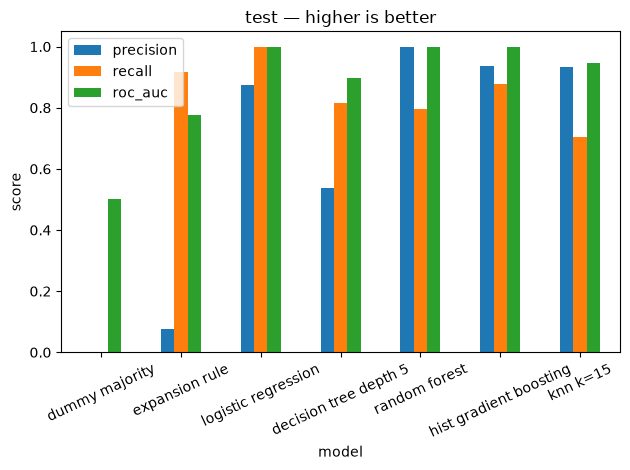

In [22]:
test_table[["precision", "recall", "roc_auc"]].plot.bar(rot=25)
plt.ylabel("score")
plt.title("test — higher is better")
plt.tight_layout()
plt.show()

## perceptron

same yes/no target. a linear perceptron is the cheap check for later deep learning.

if it is close to the forest, a neural net is unlikely to earn its cost. if it is weak, trees already cover the non-linear part.


In [23]:
perceptron = build(Perceptron())
perceptron.fit(X_train, y_train)
pred_p = perceptron.predict(X_test)
score_p = perceptron.decision_function(X_test)
class_report("perceptron", y_test, pred_p, score_p)

perceptron
  precision 0.890
  recall    0.990
  roc-auc   1.000


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: in

{'model': 'perceptron',
 'precision': 0.8899082568807339,
 'recall': 0.9897959183673469,
 'roc_auc': 0.9995317049333867}

In [24]:
clf_candidates = {
    "perceptron": Perceptron(),
    "logistic": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "random forest clf": RandomForestClassifier(n_estimators=50, class_weight="balanced", random_state=42, n_jobs=-1),
}

rows = []
for name, estimator in clf_candidates.items():
    pipe = build(estimator)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    if hasattr(pipe.named_steps["model"], "predict_proba"):
        score = pipe.predict_proba(X_test)[:, 1]
    else:
        score = pipe.decision_function(X_test)
    rows.append(class_report(name, y_test, pred, score))

pd.DataFrame(rows).set_index("model").round(3)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: in

perceptron
  precision 0.890
  recall    0.990
  roc-auc   1.000
logistic
  precision 0.875
  recall    1.000
  roc-auc   1.000


random forest clf
  precision 1.000
  recall    0.796
  roc-auc   1.000


,precision,recall,roc_auc
model,,,
perceptron,0.890,0.990,1.0
logistic,0.875,1.000,1.0
random forest clf,1.000,0.796,1.0
